# EPRLens AI — Synthetic ML Training Notebook

**SYNTHETIC — EPRLens Demo.** This notebook explains, step by step, how the two EPRLens machine-learning models were
built: a **packaging forecast** and an **anomaly detector**. It runs top to bottom on the synthetic dataset
(`data/generated/`) and re-trains the final model configurations chosen by the overnight run
(`ml/run_overnight.py`). Every metric here is measured on synthetic data — it shows the pipeline works, **not**
real-world accuracy.

In [1]:
import json, sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "synthetic-data").exists())
sys.path[:0] = [str(ROOT / "ml"), str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
CFG = yaml.safe_load((ROOT / "ml/configs/synthetic_ml.yaml").read_text())
DATA = ROOT / CFG["data_dir"] / "csv"
FMET = json.loads((ROOT / "ml/evaluation/forecast/metrics.json").read_text())
AMET = json.loads((ROOT / "ml/evaluation/anomaly/metrics.json").read_text())
print("repo root:", ROOT)

repo root: D:\EPRLens AI\syntheticml


## 1. What EPRLens AI is

EPRLens AI is a **pre-compliance assistant** for Indian businesses that put plastic packaging on the market.
A company uploads its packaging data, transaction records and invoices. EPRLens then:

* checks the records for obvious mistakes (rules),
* flags unusual patterns (machine learning),
* forecasts next month's packaging volume,
* and lets the user try "what if we used lighter packaging?" scenarios.

It is **not** a CPCB filing portal, not a legal-compliance guarantee, not a certificate issuer and not a fraud detector.

## 2. Synthetic dataset overview
The dataset was generated by `synthetic-data/generate.py` (seed 20261009). Its manifest records counts and hashes.

In [2]:
man = json.loads((ROOT / CFG["data_dir"] / "manifests/MANIFEST.json").read_text())
c = man["counts"]
overview = pd.Series({"companies": c["companies"], "products": c["products"], "transactions": c["transactions"],
                      "invoices": c["invoices"], "invoice lines": c["invoice_lines"], "recycling records": c["recycling"],
                      "forecast rows": c["forecast_panel_rows"], "labelled anomalies": c["anomaly_instances"],
                      "correct-but-tricky labels": c["hard_negative_labels"], "invoice PDFs": c["invoice_pdfs"]})
print("dataset_sha256:", man["dataset_sha256"])
overview.to_frame("count")

dataset_sha256: 0c8f6d5ad65954a9af9f4eb7f74ed187c093c69428bdd8e21212dd9eea2252d8


,count
companies,200
products,1775
transactions,174224
invoices,46501
invoice lines,179616
recycling records,14649
forecast rows,52931
labelled anomalies,3010
correct-but-tricky labels,693
invoice PDFs,1000


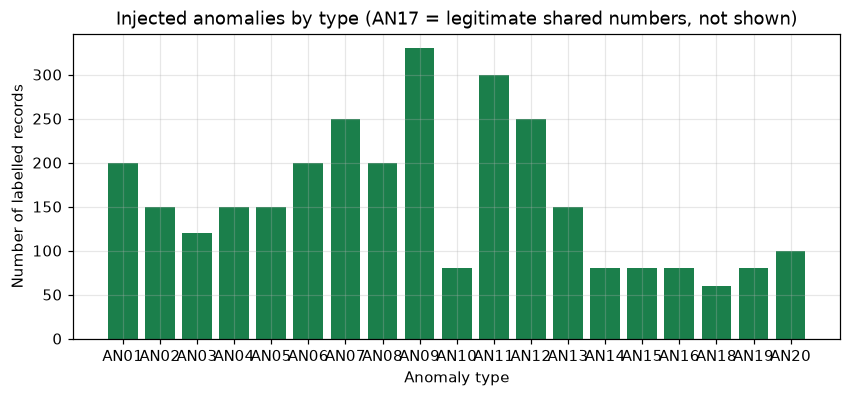

In [3]:
gt = pd.read_csv(DATA / "anomaly_ground_truth.csv", keep_default_na=False, na_values=[""])
counts = gt[gt.is_anomaly].anomaly_type.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(counts.index, counts.values, color="#1b7f4b")
ax.set_title("Injected anomalies by type (AN17 = legitimate shared numbers, not shown)")
ax.set_xlabel("Anomaly type"); ax.set_ylabel("Number of labelled records")
plt.show()

## 3. Why synthetic data?

Real company EPR operating data — invoices, sales volumes, supplier lists — is commercially sensitive and not
publicly available. We therefore generated a realistic **fictional** world (200 companies, 36 months) with known
ground truth, so every model can be measured. **Synthetic performance does not prove real-world accuracy**: the models
partly learn the generator's own rules. Real data will be messier.

## 4. Data validation
Before training, the overnight run checks every file against the manifest's SHA-256 hashes and verifies the splits.

In [4]:
val = json.loads((ROOT / "ml/evaluation/run_status.json").read_text())
splits = pd.read_csv(DATA / "splits.csv")
print("anomaly split (companies):", splits.anomaly_split.value_counts().to_dict())
print("forecast held-out companies:", int(splits.forecast_holdout.sum()))
print("stages completed:", [k for k, v in val["stages"].items() if v["status"] == "completed"])

anomaly split (companies): {'train': 120, 'test': 40, 'validation': 40}
forecast held-out companies: 40
stages completed: ['validate', 'features', 'forecast_baselines', 'forecast_search', 'forecast_final', 'anomaly_search', 'anomaly_final', 'plots', 'export', 'aws_check']


## 5. The forecasting problem

**Question:** given a product's packaging history, how many kg of packaging will it need **next month**?
Target column: `next_month_packaging_kg`. One row = one product at one month.

## 6. Forecast features (in plain words)

* **Lag features** — packaging in earlier months (1, 2, 3, 6, 11, 12 months ago).
* **Rolling means** — the average of the last 3 or 6 months.
* We divide every past value by the **latest month**, so a tiny product and a huge product look alike to the model
  ("ratio" features). The model predicts the *ratio* next month / latest month, which we multiply back into kg.
* **Seasonality** — how the industry usually moves into the target month (learned from training rows only) and how
  the product moved last year.
* Units-sales growth, packaging grams per unit, target month and industry.
Company and product IDs are **not** inputs — the model cannot memorise them.

In [5]:
from eprlens_ml import data as dt, forecast as fc, forecast_features as ff
t0 = time.time()
df, season = dt.build_forecast_frame(CFG)
print(f"built {len(df):,} rows x {len(ff.FEATURES)} features in {time.time()-t0:.1f}s")
df[["product_id", "month", "packaging_kg", "r_lag1", "r_lag12", "seasonal_shift", "season_ratio", "next_month_packaging_kg"]].head()

built 52,931 rows x 30 features in 5.2s


,product_id,month,packaging_kg,r_lag1,r_lag12,seasonal_shift,season_ratio,next_month_packaging_kg
0,PROD_000001,2023-04,524.885,1.000000,1.0,1.0,1.012221,523.457
1,PROD_000001,2023-05,523.457,1.002728,1.0,1.0,0.951276,490.042
2,PROD_000001,2023-06,490.042,1.068188,1.0,1.0,0.713083,340.435
3,PROD_000001,2023-07,340.435,1.439458,1.0,1.0,1.009644,413.358
4,PROD_000001,2023-08,413.358,0.823584,1.0,1.0,1.140067,436.444


## 7. Train / validation / test strategy

The split was fixed by the dataset generator and is **not** changed: months 1–24 train, 25–30 validation, 31–36 test
(by target month). 40 companies are held out entirely and appear only in the final test. Tuning used validation only.

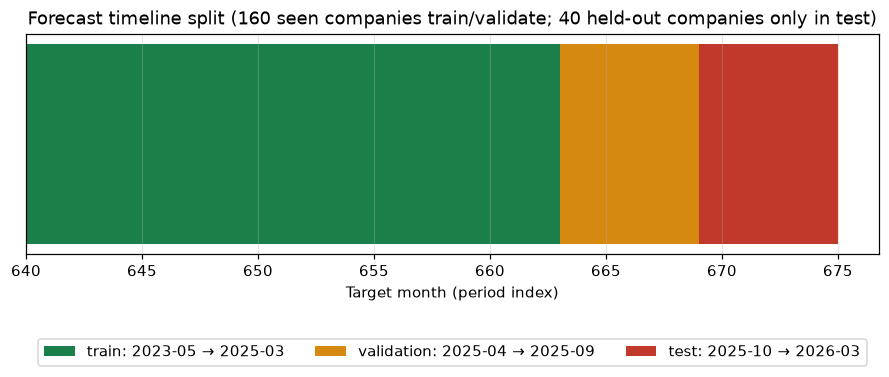

fsplit
train                    25985
test                     10542
unused_holdout_window     8347
validation                8057
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(figsize=(10, 2.6))
spans = [("train", "2023-05", "2025-03", "#1b7f4b"), ("validation", "2025-04", "2025-09", "#d68910"), ("test", "2025-10", "2026-03", "#c0392b")]
for i, (name, a, b, col) in enumerate(spans):
    a_i = pd.Period(a, "M").ordinal; b_i = pd.Period(b, "M").ordinal
    ax.barh(0, b_i - a_i + 1, left=a_i, color=col, label=f"{name}: {a} → {b}")
ax.set_yticks([]); ax.set_xlabel("Target month (period index)")
ax.set_title("Forecast timeline split (160 seen companies train/validate; 40 held-out companies only in test)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3); plt.show()
print(df.fsplit.value_counts())

## 8. Forecast baselines
F0 repeats the latest month; F1 repeats the same month last year. Any model must beat them to be useful.

In [7]:
tr, va, te = (df[df.fsplit == s] for s in ("train", "validation", "test"))
res = {}
res["F0 last value"] = (fc.metrics(va[fc.TARGET], fc.baseline_last_value(va)), fc.metrics(te[fc.TARGET], fc.baseline_last_value(te)))
sn_v, _ = fc.baseline_seasonal_naive(va); sn_t, _ = fc.baseline_seasonal_naive(te)
res["F1 seasonal naive"] = (fc.metrics(va[fc.TARGET], sn_v), fc.metrics(te[fc.TARGET], sn_t))
def table(res):
    return pd.DataFrame({k: {"val MAE kg": v[0]["mae_kg"], "val RMSE kg": v[0]["rmse_kg"], "val R²": v[0]["r2"],
                             "test MAE kg": v[1]["mae_kg"], "test RMSE kg": v[1]["rmse_kg"], "test R²": v[1]["r2"]}
                         for k, v in res.items()}).T.round(4)
table(res)

,val MAE kg,val RMSE kg,val R²,test MAE kg,test RMSE kg,test R²
F0 last value,419.4558,2219.8525,0.9656,659.7703,4229.3217,0.9675
F1 seasonal naive,528.1116,2382.0857,0.9604,726.1708,4195.3389,0.9680


Note how high R² already is for the naive baseline: packaging kg ranges over five orders of magnitude, so pooled R²
is dominated by the biggest products. That is why models are chosen on **MAE in kg**, not R².

In [8]:
comp = pd.read_csv(ROOT / "ml/evaluation/forecast/model_comparison.csv")
best = {r.algorithm: json.loads(r.params) for r in comp.itertuples() if isinstance(r.params, str)}
best

{'linear_regression_logratio': {},
 'random_forest': {'weighting': 'none',
  'n_estimators': 200,
  'min_samples_leaf': 1,
  'max_features': 1.0,
  'max_depth': 24},
 'xgboost': {'colsample_bytree': 0.9407415593496101,
  'learning_rate': 0.014256764166827952,
  'max_depth': 9,
  'min_child_weight': 3.6526887020578847,
  'reg_alpha': 0.15416238995437415,
  'reg_lambda': 2.6435585897764167,
  'subsample': 0.5697609133074022,
  'weighting': 'none'}}

## 9. Linear Regression

In [9]:
def run(algo, params):
    t0 = time.time()
    model, ptr, pva, info = fc.fit_predict(algo, params, tr, va, CFG["seed"])
    pte = fc.predict_kg(algo, model, te)
    res[{"linear_regression_raw": "F2 Linear Regression (raw)", "linear_regression_logratio": "F2 Linear Regression",
         "random_forest": "F3 Random Forest", "xgboost": "F4 XGBoost"}[algo]] = (fc.metrics(va[fc.TARGET], pva), fc.metrics(te[fc.TARGET], pte))
    print(f"{algo}: trained in {time.time()-t0:.1f}s")
    return model, pte
lr_algo = next(a for a in best if a.startswith("linear"))
lr_model, lr_pred = run(lr_algo, best[lr_algo]); table(res)

linear_regression_logratio: trained in 0.0s


,val MAE kg,val RMSE kg,val R²,test MAE kg,test RMSE kg,test R²
F0 last value,419.4558,2219.8525,0.9656,659.7703,4229.3217,0.9675
F1 seasonal naive,528.1116,2382.0857,0.9604,726.1708,4195.3389,0.9680
F2 Linear Regression,308.7179,1480.7257,0.9847,476.5826,3225.5941,0.9811


## 10. Random Forest

In [10]:
rf_model, rf_pred = run("random_forest", best["random_forest"]); table(res)

random_forest: trained in 10.6s


,val MAE kg,val RMSE kg,val R²,test MAE kg,test RMSE kg,test R²
F0 last value,419.4558,2219.8525,0.9656,659.7703,4229.3217,0.9675
F1 seasonal naive,528.1116,2382.0857,0.9604,726.1708,4195.3389,0.9680
F2 Linear Regression,308.7179,1480.7257,0.9847,476.5826,3225.5941,0.9811
F3 Random Forest,265.7260,1140.1204,0.9909,400.1396,2595.4712,0.9878


## 11. XGBoost
Gradient-boosted trees with early stopping on the validation months.

In [11]:
xgb_model, xgb_pred = run("xgboost", best["xgboost"]); table(res)

xgboost: trained in 6.5s


,val MAE kg,val RMSE kg,val R²,test MAE kg,test RMSE kg,test R²
F0 last value,419.4558,2219.8525,0.9656,659.7703,4229.3217,0.9675
F1 seasonal naive,528.1116,2382.0857,0.9604,726.1708,4195.3389,0.9680
F2 Linear Regression,308.7179,1480.7257,0.9847,476.5826,3225.5941,0.9811
F3 Random Forest,265.7260,1140.1204,0.9909,400.1396,2595.4712,0.9878
F4 XGBoost,258.1305,1104.9707,0.9915,401.5698,2749.4919,0.9863


## 12. Forecast comparison
The winner is chosen by **validation MAE** (operational error in kg). The test columns were evaluated once.

In [12]:
tab = table(res)
winner = comp.loc[comp.winner, "model"].iloc[0]
print("Selected by the overnight run:", winner, "| target R² ≥ 0.80 met:", FMET["target_met"])
tab.style.highlight_min(subset=["val MAE kg", "test MAE kg"], color="#c8f0d4").format("{:,.4f}")

Selected by the overnight run: F4 XGBoost | target R² ≥ 0.80 met: True


,val MAE kg,val RMSE kg,val R²,test MAE kg,test RMSE kg,test R²
F0 last value,419.4558,"2,219.8525",0.9656,659.7703,"4,229.3217",0.9675
F1 seasonal naive,528.1116,"2,382.0857",0.9604,726.1708,"4,195.3389",0.9680
F2 Linear Regression,308.7179,"1,480.7257",0.9847,476.5826,"3,225.5941",0.9811
F3 Random Forest,265.7260,"1,140.1204",0.9909,400.1396,"2,595.4712",0.9878
F4 XGBoost,258.1305,"1,104.9707",0.9915,401.5698,"2,749.4919",0.9863


## 13. Actual vs predicted (test)

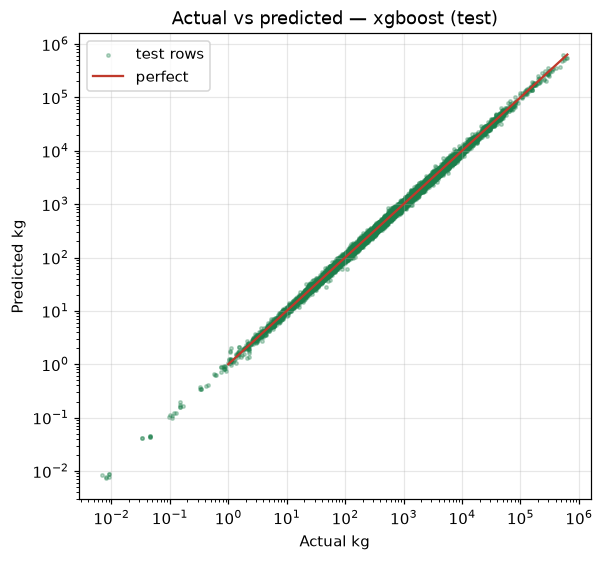

In [13]:
preds = {"linear_regression": lr_pred, "random_forest": rf_pred, "xgboost": xgb_pred}
fam = FMET["winner"]["family"]; p = preds[fam]; y = te[fc.TARGET].to_numpy()
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(y, p, s=5, alpha=0.3, color="#1b7f4b", label="test rows")
lim = [1, max(y.max(), p.max())]; ax.plot(lim, lim, color="#c0392b", label="perfect")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Actual kg"); ax.set_ylabel("Predicted kg")
ax.set_title(f"Actual vs predicted — {fam} (test)"); ax.legend(); plt.show()

## 14. Residual analysis

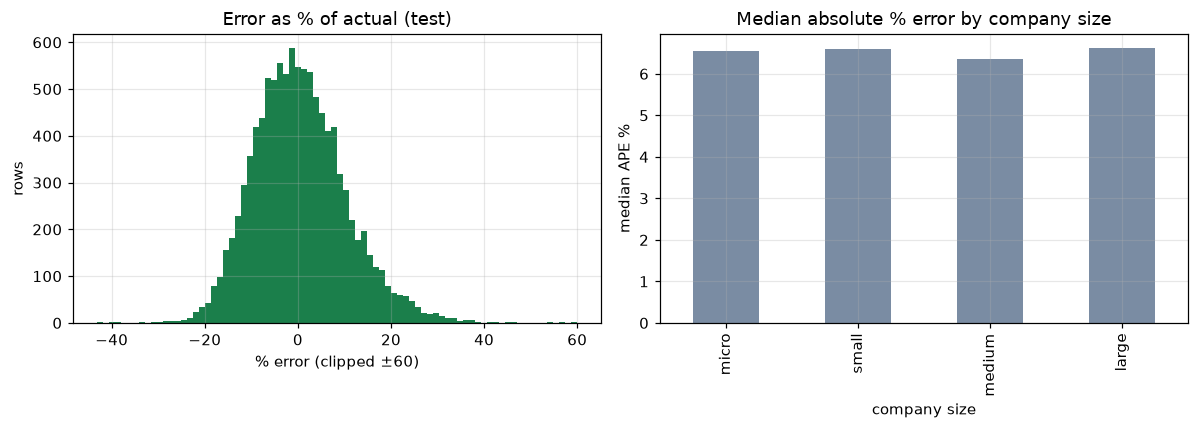

In [14]:
rel = (p - y) / np.maximum(y, 1) * 100
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(np.clip(rel, -60, 60), bins=80, color="#1b7f4b"); axs[0].set_title("Error as % of actual (test)")
axs[0].set_xlabel("% error (clipped ±60)"); axs[0].set_ylabel("rows")
size = te.company_size.to_numpy()
pd.DataFrame({"size": size, "ape": np.abs(rel)}).groupby("size").ape.median().reindex(["micro", "small", "medium", "large"]).plot.bar(ax=axs[1], color="#7a8ca3")
axs[1].set_title("Median absolute % error by company size"); axs[1].set_xlabel("company size"); axs[1].set_ylabel("median APE %")
plt.tight_layout(); plt.show()

## 15. Feature importance
Permutation importance on the validation months: how much the MAE gets worse when one feature is shuffled.

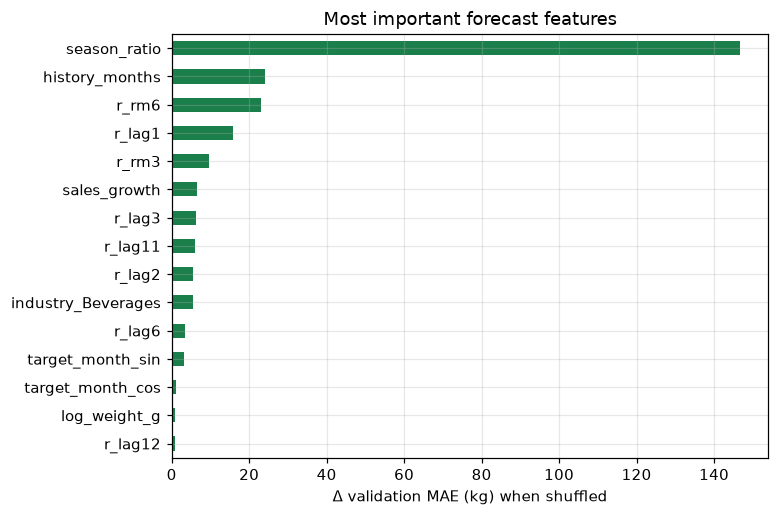

In [15]:
imp = pd.Series(FMET["permutation_importance_val_mae_kg"]).sort_values().tail(15)
ax = imp.plot.barh(figsize=(7, 5), color="#1b7f4b"); ax.set_xlabel("Δ validation MAE (kg) when shuffled")
ax.set_title("Most important forecast features"); plt.show()

## 16. Forecast conclusion

In [16]:
w = FMET["winner"]; b = FMET["test_baselines"]["F0_last_value"]
print(f"Selected: {w['family']} — test MAE {w['test']['mae_kg']:,.1f} kg (last value {b['mae_kg']:,.1f} kg), "
      f"RMSE {w['test']['rmse_kg']:,.1f} kg, R² {w['test']['r2']:.4f}")
print("Held-out companies:", {k: round(v, 4) for k, v in FMET["test_breakdown"]["held_out_companies"].items() if k in ("mae_kg", "r2")})

Selected: xgboost — test MAE 401.6 kg (last value 659.8 kg), RMSE 2,749.5 kg, R² 0.9863
Held-out companies: {'mae_kg': 994.512, 'r2': 0.9855}


## 17. What is an anomaly?
A record that looks wrong: a quantity with an extra zero, a duplicate invoice, a cancelled invoice still counted, a
recycler claiming more recycled than collected, or a month with an implausible spike. Flags are prompts for review —
not accusations.

## 18. Why rules + ML?
**Rules** catch known mistakes exactly (duplicates, missing fields, unit errors, invoice ≠ record). **Isolation Forest**
looks for *unusual* records that no rule describes — here mainly sudden monthly spikes (AN09).

## 19. Injected anomaly distribution

In [17]:
from eprlens_ml import data as dt, anomaly as an, anomaly_features as af
from rules import anomaly_rules as ar
t0 = time.time()
splits_df = pd.read_csv(DATA / "splits.csv")
records, rate_ref, (labels, gt2, sp) = dt.build_records(CFG, set(splits_df[splits_df.anomaly_split == "train"].company_id))
lab = dt.build_labels(records, labels, gt2, sp).reset_index(drop=True)
feat = dt.anomaly_feature_table(records, rate_ref)
print(f"{len(records):,} records ({time.time()-t0:.0f}s)"); pd.crosstab(lab.anomaly_type.fillna("normal"), lab.split)

59,235 records (20s)


split,test,train,validation
anomaly_type,,,
AN01,38,113,49
AN02,30,86,34
AN03,24,70,26
AN04,32,88,30
AN05,22,88,40
AN06,55,108,37
AN07,41,164,45
AN08,27,132,40
AN09,103,381,132


## 20. Deterministic rules — examples

In [18]:
tol = AMET["rules_tolerance"]
demo = next(r for r in records if r["record_type"] == "invoice" and r["company_id"] == "COMP_0001"
            and any(f["triggered"] and f["rule_id"] == "QTY_RATIO_POW10" for f in ar.run_rules(r, tol)))
pd.DataFrame([f for f in ar.run_rules(demo, tol) if f["triggered"]])

,rule_id,triggered,severity,reason
0,QTY_MATCH_TOL,True,medium,line3: invoice 44131.531 kg vs record 4413.153 kg
1,QTY_RATIO_POW10,True,high,record differs by a power of ten on lines [3]


## 21. Isolation Forest in one paragraph
It builds many random trees that split the data at random values. Unusual records get isolated in **few** splits, so
their average path is short and their *anomaly score* is high. No labels are used to train it.

## 22. Feature engineering (no labels!)

In [19]:
af.assert_no_label_fields(af.FEATURES); af.assert_no_label_fields(list(feat.columns))
print("features:", af.FEATURES)
feat.describe().T[["mean", "50%", "max"]].round(3)

features: ['log_amount_inr', 'log_total_kg', 'n_lines', 'max_qty_log_ratio', 'item_spike', 'item_mom', 'issuer_rel_amount', 'issuer_frequency', 'rate_rel', 'weight_rel', 'type_CREDIT_NOTE', 'type_FG_SALES', 'type_IMPORT_COMMERCIAL', 'type_MULTI_MATERIAL', 'type_PKG_COMPONENT', 'type_PKG_PURCHASE', 'type_RECYCLING_SERVICE', 'type_RETURN', 'type_WASTE_PROCUREMENT']


,mean,50%,max
log_amount_inr,13.751,13.946,21.016
log_total_kg,6.973,7.261,14.567
n_lines,3.700,2.000,12.000
max_qty_log_ratio,0.070,0.000,7.824
item_spike,0.151,0.022,9.718
item_mom,0.122,0.000,9.228
issuer_rel_amount,-0.105,0.000,6.907
issuer_frequency,3.259,2.944,5.609
rate_rel,0.026,0.000,2.760
weight_rel,0.004,0.000,2.702


## 23. Rules-only evaluation

In [20]:
rmat = [[f["rule_id"] for f in ar.run_rules(r, tol) if f["triggered"]] for r in records]
rpred = np.array([1 if x else 0 for x in rmat]); y = lab.y.to_numpy(); test = (lab.split == "test").to_numpy()
pd.Series(an.binary_metrics(y[test], rpred[test])).to_frame("rules only (test)").T.round(4)

,precision,recall,f1,specificity,fpr,tp,fp,tn,fn,n,positives
rules only (test),1.0,0.8309,0.9076,1.0,0.0,506.0,0.0,11096.0,103.0,11705.0,609.0


## 24. Isolation-Forest-only evaluation
Parameters and threshold were chosen on validation companies by the overnight run.

In [21]:
params = AMET["params"]; thr = AMET["thresholds"]
idx = {r: i for i, r in enumerate(lab.record_id)}; fi = np.array([idx[r] for r in feat.record_id])
X = feat[af.FEATURES].to_numpy(float); split = lab.split.to_numpy()
mask = np.array([split[i] == "train" and (params["fit_on"] == "all" or rpred[i] == 0) for i in fi])
model = an.fit_if(params, X[mask], CFG["seed"])
s = an.full_scores(lab, fi, an.if_scores(model, X))
ipred = (s >= thr["iforest"]).astype(int)
pd.Series(an.binary_metrics(y[test], ipred[test])).to_frame("Isolation Forest only (test)").T.round(4)

,precision,recall,f1,specificity,fpr,tp,fp,tn,fn,n,positives
Isolation Forest only (test),0.4534,0.2315,0.3065,0.9847,0.0153,141.0,170.0,10926.0,468.0,11705.0,609.0


## 25. Combined system (rules OR Isolation Forest)

In [22]:
cpred = np.maximum(rpred, (s >= thr["combined"]).astype(int))
rows = {n: an.binary_metrics(y[test], p[test]) for n, p in (("rules only", rpred), ("IF only", ipred), ("rules + IF", cpred))}
summary = pd.DataFrame(rows).T[["precision", "recall", "f1", "specificity", "fpr", "tp", "fp", "fn"]]
summary.round(4)

,precision,recall,f1,specificity,fpr,tp,fp,fn
rules only,1.0000,0.8309,0.9076,1.0000,0.0000,506.0,0.0,103.0
IF only,0.4534,0.2315,0.3065,0.9847,0.0153,141.0,170.0,468.0
rules + IF,0.9286,0.8966,0.9123,0.9962,0.0038,546.0,42.0,63.0


## 26. Confusion matrix (rules + IF, test)

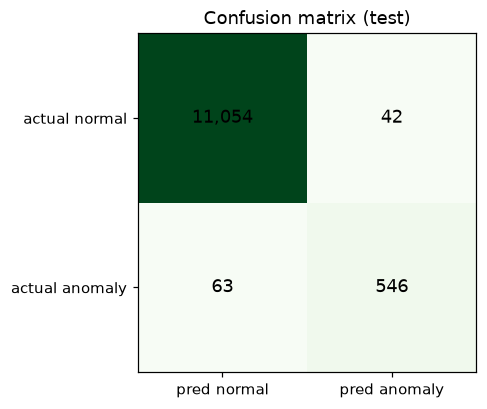

In [23]:
m = rows["rules + IF"]; cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.imshow(cm, cmap="Greens")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=12)
ax.set_xticks([0, 1], ["pred normal", "pred anomaly"]); ax.set_yticks([0, 1], ["actual normal", "actual anomaly"])
ax.set_title("Confusion matrix (test)"); ax.grid(False); plt.show()

## 27. Precision / recall / F1

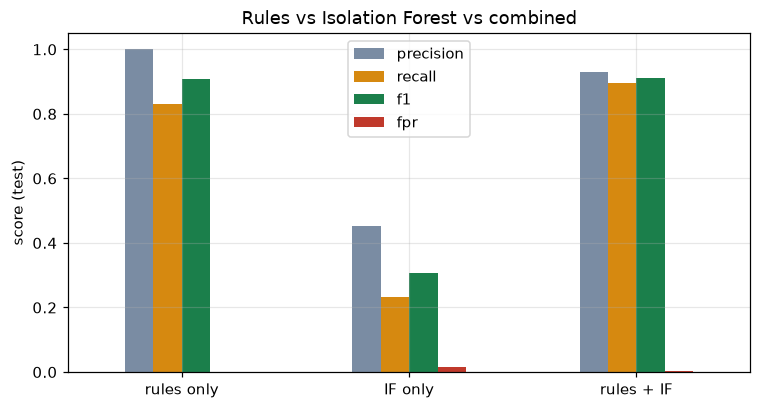

target F1 ≥ 0.80 with FPR ≤ 0.10: True


In [24]:
ax = summary[["precision", "recall", "f1", "fpr"]].plot.bar(figsize=(8, 4), rot=0, color=["#7a8ca3", "#d68910", "#1b7f4b", "#c0392b"])
ax.set_ylim(0, 1.05); ax.set_ylabel("score (test)"); ax.set_title("Rules vs Isolation Forest vs combined"); plt.show()
print("target F1 ≥ 0.80 with FPR ≤ 0.10:", AMET["target_met"])

## 28. Performance by anomaly type

In [25]:
te_lab = lab[test]
per = {}
for name, p in (("rules", rpred), ("IF", ipred), ("rules + IF", cpred)):
    bt, bg = an.breakdown(te_lab, pd.Series(p, index=lab.index))
    per[name] = {k: v["recall"] for k, v in bt.items()}
per_df = pd.DataFrame(per); per_df["n"] = te_lab[te_lab.y == 1].anomaly_type.value_counts()
per_df.round(3)

,rules,IF,rules + IF,n
AN01,1.0,0.737,1.000,38
AN02,1.0,0.067,1.000,30
AN03,1.0,0.042,1.000,24
AN04,1.0,0.000,1.000,32
AN05,1.0,0.045,1.000,22
AN06,1.0,0.000,1.000,55
AN07,1.0,0.073,1.000,41
AN08,1.0,0.519,1.000,27
AN09,0.0,0.709,0.388,103
AN10,1.0,0.857,1.000,14


## 29. False-positive analysis — correct but tricky records
The 693 AN17 records legitimately share an invoice number (the EPR handbook allows up to 5). They must **not** be
flagged as duplicates.

In [26]:
_, bg = an.breakdown(te_lab, pd.Series(cpred, index=lab.index))
pd.DataFrame(bg).T

,n,false_positives,fpr
legit_special_document,410.0,4.0,0.009756
routine_normal,10540.0,38.0,0.003605
tricky_AN17_shared_number,146.0,0.0,0.000000


## 30. Final anomaly model

In [27]:
print("system:", AMET["chosen_system"], "| IF params:", params, "| thresholds:", thr, "| rules tolerance:", tol)
print(json.dumps(AMET["systems"][AMET["chosen_system"]]["test"], indent=1))

system: rules_plus_iforest | IF params: {'n_estimators': 100, 'max_samples': 'auto', 'max_features': 0.7, 'fit_on': 'rules_clean', 'bootstrap': False} | thresholds: {'combined': 0.5386695519803739, 'iforest': 0.515166130192634} | rules tolerance: {'qty_tolerance_kg': 0.01, 'qty_tolerance_rel': 0.0005}
{
 "precision": 0.9285714285714286,
 "recall": 0.896551724137931,
 "f1": 0.912280701754386,
 "specificity": 0.9962148521989906,
 "fpr": 0.0037851478010093587,
 "tp": 546,
 "fp": 42,
 "tn": 11054,
 "fn": 63,
 "n": 11705,
 "positives": 609
}


## 31. Limitations
* Synthetic data: models learn the generator's patterns; real data will be harder.
* The rule layer mirrors the injected anomaly catalogue, so its near-perfect precision is expected by construction.
* AN09 (spikes) is the honest test of the ML layer.
* Pooled R² is dominated by large products; judge forecasts by MAE and % error.
* Results support human review; they are not compliance determinations.

## 32. AWS deployment — which files AWS consumes

In [28]:
for d in ("forecast", "anomaly"):
    folder = ROOT / f"ml/artifacts/{d}/v1"
    print(f"s3://<bucket>/models/{d}/v1/  <-  {folder.relative_to(ROOT)}")
    for f in sorted(folder.iterdir()):
        print(f"    {f.name:28s} {f.stat().st_size/1e6:8.3f} MB")
print("\nReference handlers: ml/aws_examples/lambda_forecast_handler.py, lambda_anomaly_handler.py")
print("Guide: docs/EPRLens_ML_to_AWS_Engineer_Guide.pdf and ml/AWS_HANDOFF.md")

s3://<bucket>/models/forecast/v1/  <-  ml\artifacts\forecast\v1
    feature_schema.json             0.002 MB
    features.py                     0.006 MB
    model.onnx                      7.101 MB
    model_metadata.json             0.004 MB
    preprocessor.joblib             0.003 MB
    requirements-lambda.txt         0.000 MB
    sample_input.json               0.002 MB
    sample_output.json              0.000 MB
    SHA256SUMS.txt                  0.001 MB
s3://<bucket>/models/anomaly/v1/  <-  ml\artifacts\anomaly\v1
    feature_schema.json             0.001 MB
    features.py                     0.005 MB
    isolation_forest.joblib         1.006 MB
    model_metadata.json             0.004 MB
    preprocessor.joblib             0.020 MB
    requirements-lambda.txt         0.000 MB
    rules.py                        0.009 MB
    rules_config.json               0.002 MB
    sample_input.json               0.002 MB
    sample_output.json              0.000 MB
    SHA256SUMS.txt 